In [148]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [149]:
rng = np.random.default_rng(42)
mu1=np.array([2,4])

mu2=np.array([2.7,6])

Sigma_1 = np.array([[0.8, 0.3],[0.3, 0.5]])

Sigma_2 = np.array([[0.6, -0.2],[-0.2, 0.8]])

X1=rng.multivariate_normal(mu1,Sigma_1, size=100)
X2=rng.multivariate_normal(mu2,Sigma_2, size=100)

X=np.vstack([X1,X2])
X=rng.permutation(X) 
real=np.vstack([np.zeros(100),np.ones(100)])

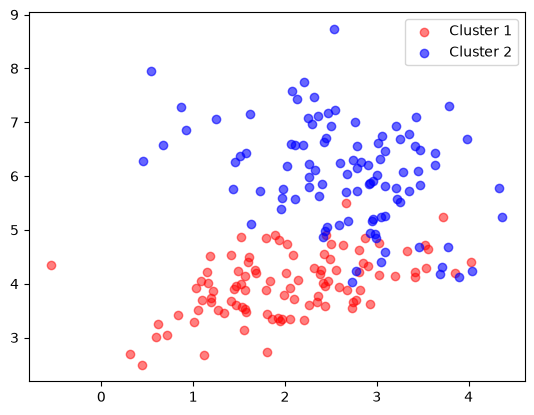

In [150]:
plt.scatter(X1[:,0],X1[:,1], color='red', label='Cluster 1', alpha=0.5)
plt.scatter(X2[:,0],X2[:,1], color='blue', label='Cluster 2',alpha=0.6)
plt.legend()
plt.show()

In [151]:
class EM_Gaussian:
    def __init__(self,n_clusters=3, max_iter=1000, tol=1e-4):
        self.n_clusters=n_clusters
        self.max_iter=max_iter
        self.tol=tol
        self.mu=None
        self.Sigma=None
        self.pi=None
        self.resp=None
    
    def log_densidad_gaussiana(self,X, mu, sigma):
        n_muestras, n_features= X.shape
        
        L=np.linalg.cholesky(sigma)

        log_det=2*np.sum(np.log(np.diagonal(L)))

        diff=X-mu

        y=np.linalg.solve(L, diff.T)

        mahalanobi=np.sum(y**2, axis=0)

        log_prob=-0.5*(n_features*np.log(np.pi*2)+ log_det + mahalanobi)

        return log_prob
    
    def logsumexp(self,A,axis=1):
        m=np.max(A, axis=axis, keepdims=True)
        suma=m+np.log(np.sum(np.exp(A-m), axis=axis, keepdims=True))
        return suma

    def e_paso(self, X):
        N,D=X.shape
        log_resp=np.zeros((N, self.n_clusters))
        for k in range(self.n_clusters):
            log_resp[:,k]=np.log(self.pi[k])+self.log_densidad_gaussiana(X, self.mu[k], self.Sigma[k])
        log_marginal=self.logsumexp(log_resp, axis=1)

        responsabilidades=np.exp(log_resp-log_marginal)
        log_likelihood=np.sum(log_marginal)
        return responsabilidades, log_likelihood

    def m_paso(self, X, responsabilidades, medias, covarianzas):
        N,D=X.shape
        N_k=np.sum(responsabilidades, axis=0)
        medias=np.zeros((self.n_clusters, D))
        covarianzas=np.zeros((self.n_clusters,D,D))
        pis=N_k/N
        cov_global=np.cov(X, rowvar=False, bias=True)
        cov_global=np.atleast_2d(cov_global)
        for k in range(self.n_clusters):
            medias[k]=responsabilidades[:,k]@X/N_k[k]
            diff=X-medias[k]
            covarianzas[k]=(diff.T@np.diag(responsabilidades[:,k]))@diff/N_k[k]
            pis[k]=N_k[k]/N
        return medias, covarianzas, pis

    def fit(self, X):
        N,D=X.shape
        self.mu=X[np.random.choice(N, self.n_clusters, replace=False)]
        self.Sigma=np.array([np.cov(X, rowvar=False, bias=True)]*self.n_clusters)
        self.pi=np.ones(self.n_clusters)/self.n_clusters
        log_likelihoods=[]
        for i in range(self.max_iter):
            responsabilidades, log_likelihood=self.e_paso(X)
            log_likelihoods.append(log_likelihood)
            self.mu, self.Sigma, self.pi=self.m_paso(X, responsabilidades, self.mu, self.Sigma)
            if i>0 and np.abs(log_likelihood-log_likelihoods[-2])<self.tol:
                break
        self.clases=np.argmax(responsabilidades, axis=1)
        return log_likelihoods

        
        

    

In [152]:
X=np.array(X)

In [153]:
model=EM_Gaussian(n_clusters=2, max_iter=1000, tol=1e-4)
log_likelihoods=model.fit(np.array(X))

In [154]:
model.clases

array([1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 1])

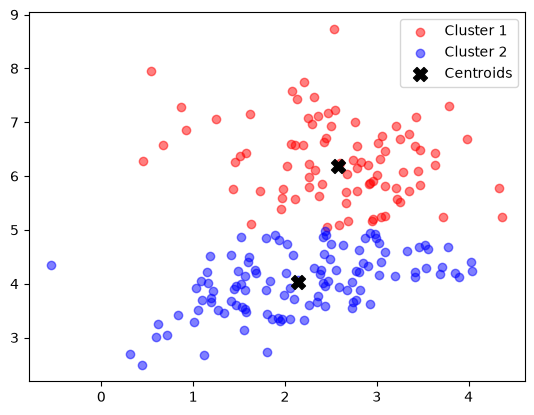

In [155]:
c1=X[model.clases==0]
c2=X[model.clases==1]
plt.scatter(c1[:,0],c1[:,1], color='red', label='Cluster 1', alpha=0.5)
plt.scatter(c2[:,0],c2[:,1], color='blue', label='Cluster 2', alpha=0.5)
plt.scatter(model.mu[:,0], model.mu[:,1], color='black', marker='X', s=100, label='Centroids')
plt.legend()
plt.show()